In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import corner
import glob
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt


In [2]:
for path in glob.glob("*.npy.npz"):
    print(path)


mc_z.npy.npz
mc0_alive.npy.npz
mc1_alive.npy.npz
mc2_alive.npy.npz
mc3_alive.npy.npz
mc4_dead.npy.npz


In [3]:
loc=['mc_z.npy.npz',
'mc0_alive.npy.npz',
'mc1_alive.npy.npz',
'mc2_alive.npy.npz'
]

mc_z.npy.npz
1.3271550842562419e-12


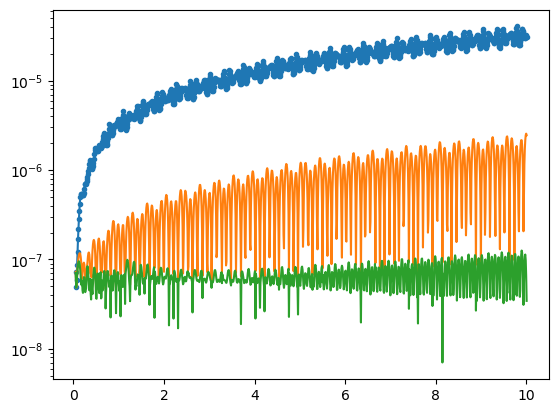

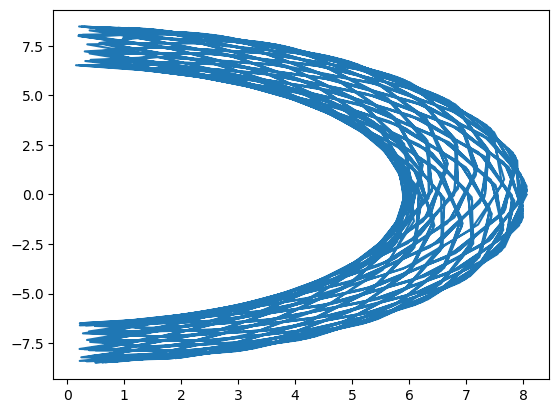

mc0_alive.npy.npz
2.311585397628155e-14


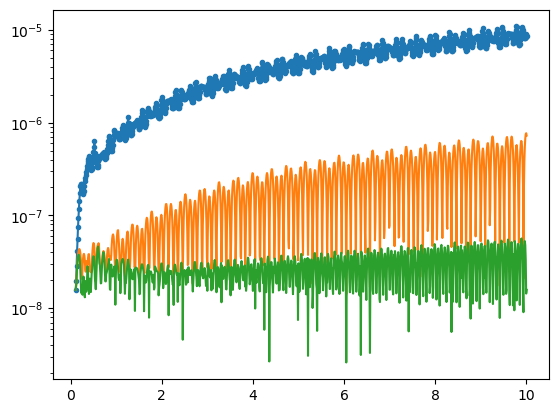

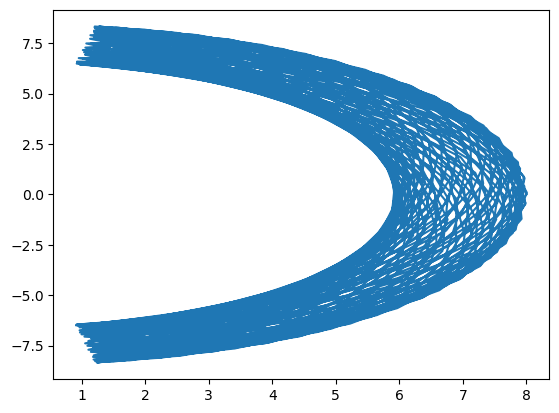

mc1_alive.npy.npz
1.612080411602834e-13


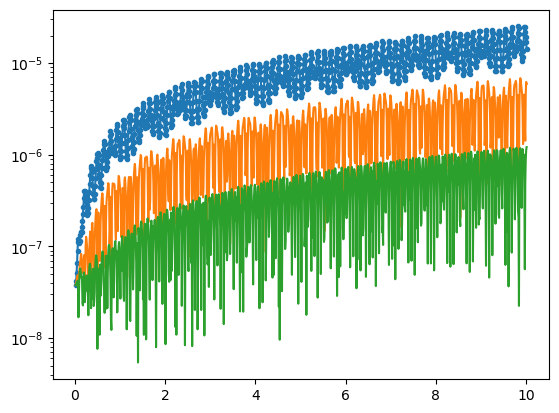

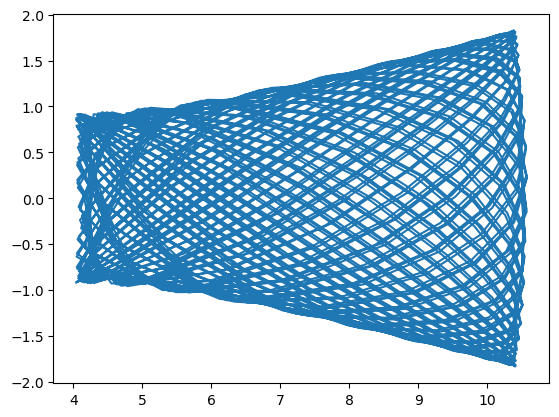

mc2_alive.npy.npz
1.7419410103676797e-14


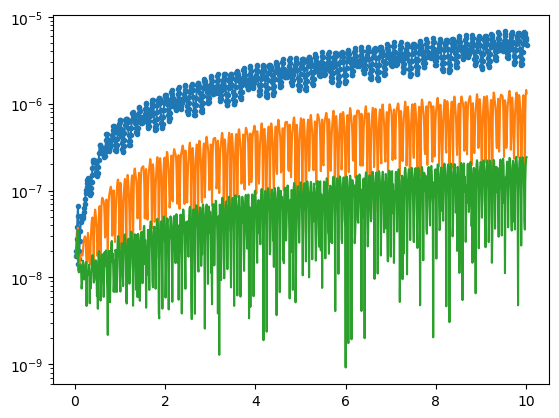

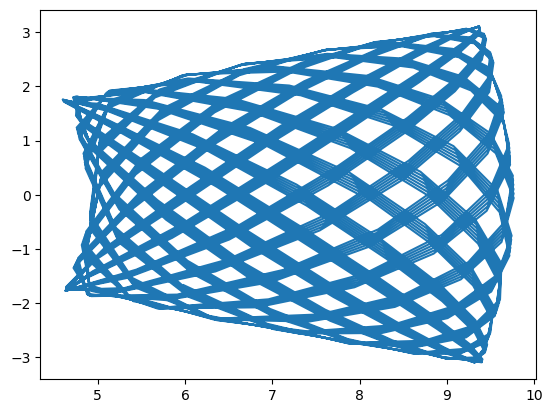

In [4]:
#for path in glob.glob("*.npy.npz"):
for path in loc:
    print(path)
    d=np.load(path)
    mcp_xv     = d['mcp_xv']
    mcp_mass   = d['mcp_mass']
    mc_mass    = d['mc_mass']
    mc_radius  = d['mc_radius']
    color      = d['color']
    mc_start   = d['mc_start']
    mc_end     = d['mc_end']
    t          = d['t_array']
    o          = d['orbit_array']
    SD         = d['SD']
    SD_t       = d['SD_t']
    SD_r       = d['SD_r']
    plt.plot(SD_t,SD[:,0],marker='.')
    plt.plot(SD_t,SD[:,1])
    plt.plot(SD_t,SD[:,2])
    print(mc_mass)
    plt.yscale('log')
    plt.show()
    plt.plot(np.linalg.norm(o[:,0:2],axis=1),o[:,2])
    plt.show()
    #plt.xscale('log')


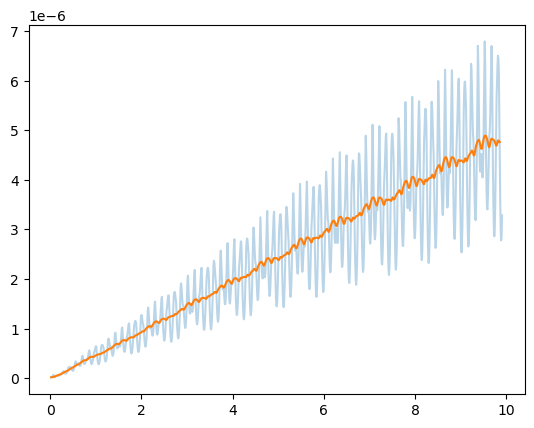

In [5]:
w = 30
y_smooth = np.convolve(SD[:,0], np.ones(w)/w, mode='same')

plt.plot(SD_t[:-10], SD[:-10,0], alpha=0.3)
plt.plot(SD_t[:-w//2], y_smooth[:-w//2])
plt.show()


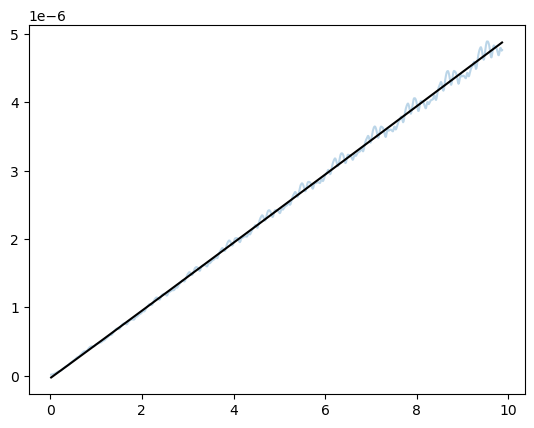

4.901373133178815e-07 1.0066729675738495 -3.2692898508073054e-08


In [6]:

def f(t, a, x, c):
    return a * t**x + c

t_fit = SD_t[:-w//2]
y_fit = y_smooth[:-w//2]

popt, _ = curve_fit(f, t_fit, y_fit)
a, x, c = popt

plt.plot(t_fit, y_fit, alpha=0.3)
plt.plot(t_fit, f(t_fit, *popt),'k')
plt.show()
print(a,x,c)


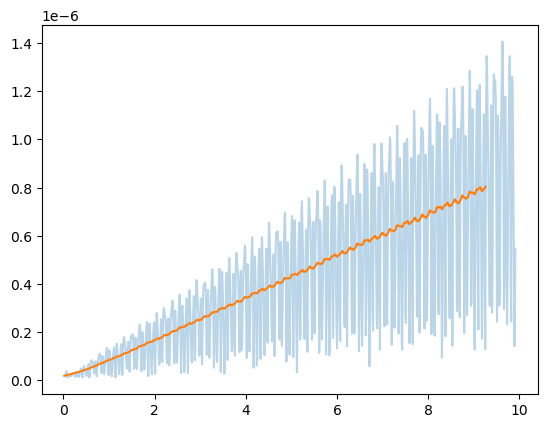

In [7]:
w = 150
y_smooth = np.convolve(SD[:,1], np.ones(w)/w, mode='same')

plt.plot(SD_t[:-10], SD[:-10,1], alpha=0.3)
plt.plot(SD_t[:-w//2], y_smooth[:-w//2])
plt.show()


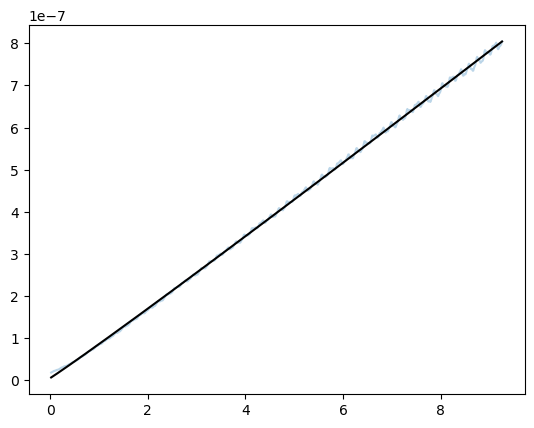

8.071611796055811e-08 1.0300127647343411 5.172107827472094e-09


In [8]:
t_fit = SD_t[:-w//2]
y_fit = y_smooth[:-w//2]

popt, _ = curve_fit(f, t_fit, y_fit)
a, x, c = popt

plt.plot(t_fit, y_fit, alpha=0.3)
plt.plot(t_fit, f(t_fit, *popt),'k')
plt.show()
print(a,x,c)


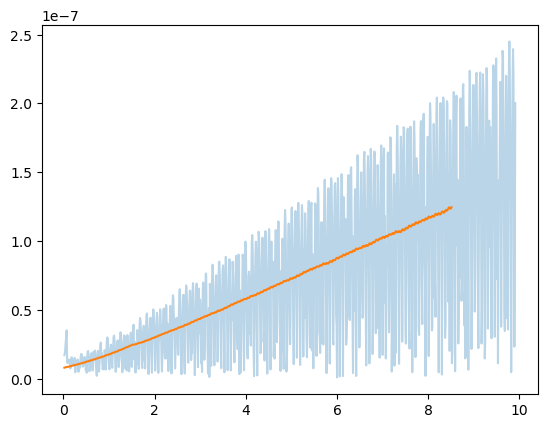

In [9]:
w = 300
n=0
y_smooth = np.convolve(SD[n:,2], np.ones(w)/w, mode='same')

plt.plot(SD_t[n:-10], SD[n:-10,2], alpha=0.3)
plt.plot(SD_t[n:-w//2], y_smooth[:-w//2])
plt.show()


In [61]:
t_fit = SD_t[:-w//2]
y_fit = y_smooth[:-w//2]

popt, _ = curve_fit(f, t_fit, y_fit)
a, x, c = popt

plt.plot(t_fit, y_fit, alpha=0.3)
plt.plot(t_fit, f(t_fit, *popt),'k')
plt.show()
print(a,x,c)


RuntimeError: Optimal parameters not found: Number of calls to function has reached maxfev = 800.

In [ ]:
from scipy.integrate import quad
import numpy as np
def dndlog10Mpow(power):    
    M=10**power
    return (M**(-0.5))*np.exp(-M/1e-2)*np.exp(-1e-14/M) #cutoff set to 1e-2 and 1e-14 M_sun and \gamma =0.5

def prob(power):
    return dndlog10Mpow(power)/quad(dndlog10Mpow, -100,100)[0]

M=np.linspace(-14, -1, 1000)
def get_mass():
    while True:
        x = np.random.uniform(-17, 1)
        u = np.random.uniform(0, 1)
        if u < prob(x):
            return 10**x   

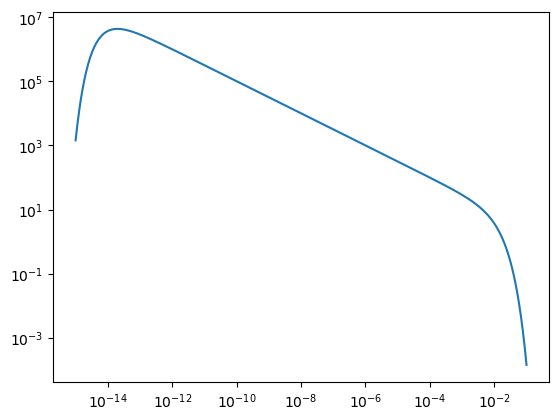

In [ ]:

M=np.linspace(-15,-1,1000)
plt.plot(10**M,dndlog10Mpow(M))
plt.xscale('log')
plt.yscale('log')